## **Simulation of Mn- and Cr-doped DMS**

## 1. **Theoretical Framework $(Ga_{1-x}Fe_xSb)$**

The main objective is to study electron-induced ferromagnetism in iron-doped gallium antimonide (GaSb:Fe)—a promising material for spintronics applications, given its potential to operate at room temperature.

The physical model is based on the following considerations:

A zinc-blende crystal structure with a lattice constant of $a = 6.09\text{ \AA}$ is assumed.
The magnetic ions ($\text{Fe}^{3+}$) have a total spin of $S = 5/2$.
The Heisenberg Hamiltonian is used to describe the exchange interactions between the localized spins.
The Holstein-Primakoff transformation is employed to treat spin excitations as bosons (magnons).
The Green's function formalism is applied to obtain the statistical averages required for the thermodynamics of the system.

## 2. **Mathematical Development**

### 2.1 Heisenberg Hamiltonian

The system is described by the Heisenberg Hamiltonian for a ferromagnet, accounting for exchange interactions $J_{ij}$ between neighboring sites $i$ and $j$:

$$
H = -\sum_{\langle i,j\rangle} J(R_{i}-R_{j})\hat{S}_{i} \cdot \hat{S}_{j}
$$

Using ladder operators (raising and lowering operators, $\hat{S}^+$ and $\hat{S}^-$) and applying the Holstein-Primakoff transformation for low temperatures (where the spin deviation is small), the Hamiltonian is reduced to a quadratic form in terms of magnon creation ($a_k^\dagger$) and annihilation ($a_k$) operators.
For the non-interacting bilinear part ($H_0$), we obtain:

$$
H_{0} = \sum_{k} \omega_{k} a_{k}^{+} a_{k}
$$

### 2.2 Dispersion Relation

For long wavelengths ($ka \ll 1$) and averaging over the impurity concentration $x$, the magnon energy ($\omega_k$) is approximated as:

$$
\omega_{k} = 2 J x S a^2 k^{2}
$$

Where $J$ is the exchange energy, $S$ is the spin, $x$ is the doping concentration, and $k$ is the wave vector.

### 2.3 Magnetization and Curie Temperature

The spontaneous magnetization $M_S(T)$ decreases with temperature due to the thermal excitation of magnons. The reduced magnetization relationship is derived by integrating the density of states:

$$
\frac{M_{S}(T)}{M_{S}(0)} = 1 - \frac{1}{nS} 0.0587 \left(\frac{k_{B}T}{2JxSa^{2}}\right)^{\frac{3}{2}} = 1 - \left(\frac{T}{T_c}\right)^{\frac{3}{2}}
$$

The Curie temperature ($T_C$) is defined as the temperature at which the spontaneous magnetization disappears. By setting the above equation to zero, the analytical expression for $T_C$ is obtained:

$$
T_{c} = \left(x \frac{2JS}{k_{B}}\right) \left(\frac{nSa^{3}}{0.0587}\right)^{\frac{2}{3}}
$$

Where $n$ is the carrier density.

### 2.4 Specific Heat Capacity

The heat capacity of magnons is obtained by differentiating the internal energy with respect to temperature:

$$
C_{magnon} \propto \frac{1}{(2JxSa^{2})^{3/2}} k_{B}^{5/2} T^{3/2}
$$

### **Simulation**

Maximum Tc at x=0.2: 330.36 K


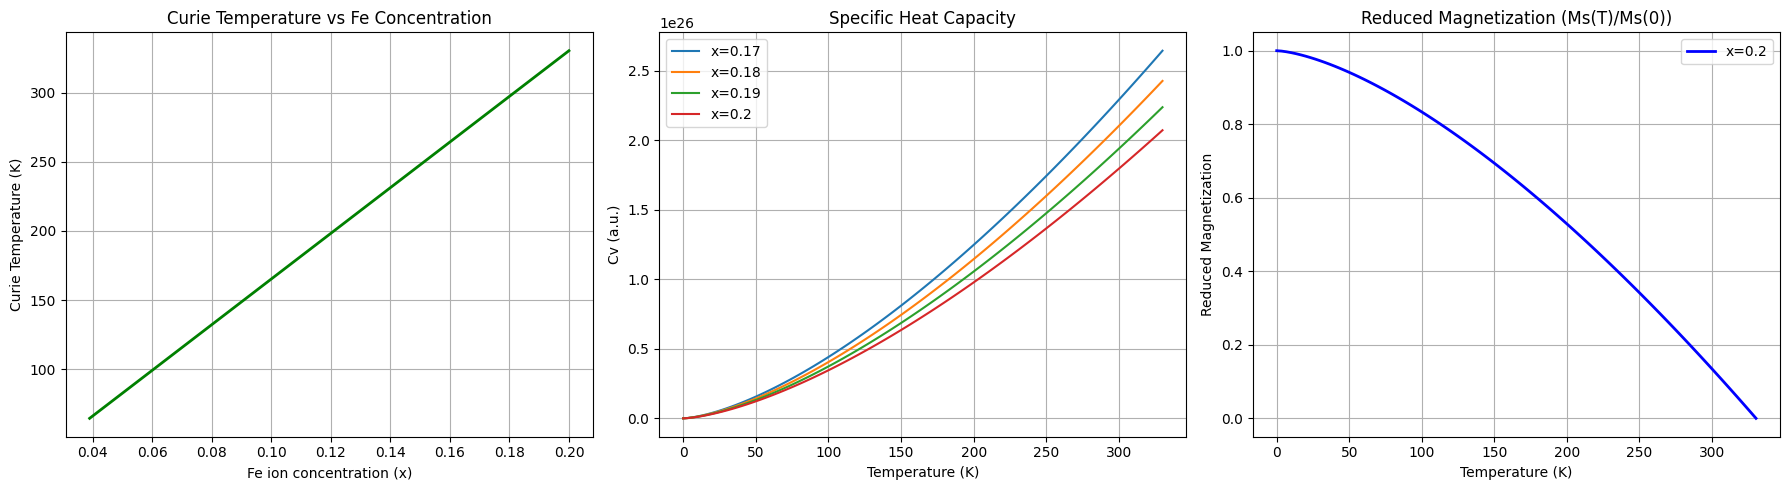

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# SYSTEM PARAMETERS
# ==========================================
# Exchange constant (J) in meV
J = 10.0
# Lattice constant (a) in Angstroms converted to meters
a_angstrom = 6.09
a = a_angstrom * 1e-10
# Spin of the Fe3+ ion
S = 2.5 # (5/2)
# Boltzmann constant (kB) in meV/K
kB = 0.08625
# Carrier density (n) in m^-3
# Note: The paper uses approx 5e26 m^-3 in the results section
n = 5e26

# Constant factor of the integral (according to Eq 22 and 26 of the paper)
integral_factor = 0.0587

# ==========================================
# 1. CURIE TEMPERATURE (Tc) CALCULATION
# Equation (26)
# ==========================================

# Fe concentration range (x) from 0.039 to 0.2
x_values = np.linspace(0.039, 0.2, 100)

def calculate_Tc(x, J, S, kB, n, a, factor):
    # Term 1: (x * 2JS / kB)
    term1 = x * (2 * J * S) / kB
    # Term 2: (n * S * a^3 / 0.0587)^(2/3)
    term2 = ((n * S * (a**3)) / factor)**(2/3)
    return term1 * term2

Tc_values = calculate_Tc(x_values, J, S, kB, n, a, integral_factor)

# Print the maximum result to verify with the paper (330.4 K)
print(f"Maximum Tc at x=0.2: {Tc_values[-1]:.2f} K")

# ==========================================
# 2. HEAT CAPACITY CALCULATION
# Equation (29)
# ==========================================

T_range = np.linspace(0, 330, 100)
# Calculated for different concentrations as in Figure 2
concentrations = [0.17, 0.18, 0.19, 0.20]

def calculate_Cv(T, x, J, S, a, kB):
    # Constant prefix
    const = 0.113
    # Denominator: (2JxSa^2)^(3/2)
    # Note: Care must be taken here with units to ensure consistency.
    # The paper plots high relative values, we will follow the literal formula.
    denom = (2 * J * x * S * (a**2))**(1.5)

    # Variable numerator: kB^(5/2) * T^(3/2)
    num = (kB**2.5) * (T**1.5)

    return const * (1/denom) * num

# ==========================================
# 3. REDUCED MAGNETIZATION CALCULATION
# Equation (24)
# ==========================================

# We use x = 0.2 for the magnetization
x_mag = 0.2
Tc_max = calculate_Tc(x_mag, J, S, kB, n, a, integral_factor)
T_mag = np.linspace(0, Tc_max, 100)

def calculate_reduced_M(T, Tc):
    # M(T)/M(0) = 1 - (T/Tc)^(3/2)
    return 1 - (T / Tc)**1.5

M_values = calculate_reduced_M(T_mag, Tc_max)

# ==========================================
# PLOTTING (Reproduction of Figures 1, 2, and 3)
# ==========================================

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Tc vs Concentration
axs[0].plot(x_values, Tc_values, color='green', linewidth=2)
axs[0].set_title('Curie Temperature vs Fe Concentration')
axs[0].set_xlabel('Fe ion concentration (x)')
axs[0].set_ylabel('Curie Temperature (K)')
axs[0].grid(True)

# Plot 2: Heat Capacity vs Temperature
# Note: The exact magnitude of the Y-axis depends on unspecified mass units,
# the functional trend is shown.
for x in concentrations:
    Cv = calculate_Cv(T_range, x, J, S, a, kB)
    axs[1].plot(T_range, Cv, label=f'x={x}')
axs[1].set_title('Specific Heat Capacity')
axs[1].set_xlabel('Temperature (K)')
axs[1].set_ylabel('Cv (a.u.)')
axs[1].legend()
axs[1].grid(True)

# Plot 3: Reduced Magnetization vs Temperature
axs[2].plot(T_mag, M_values, color='blue', linewidth=2, label='x=0.2')
axs[2].set_title('Reduced Magnetization (Ms(T)/Ms(0))')
axs[2].set_xlabel('Temperature (K)')
axs[2].set_ylabel('Reduced Magnetization')
axs[2].legend()
axs[2].grid(True)

plt.tight_layout()
plt.show()

### **PLOTTING & SAVING (Figures 1, 2, and 3)**

In [ ]:
import os

# ==========================================
# PLOTTING & SAVING (Figures 1, 2, and 3)
# ==========================================

# Create the 'figures' directory if it doesn't exist
os.makedirs('figures', exist_ok=True)

# ------------------------------------------
# Figure 1: Tc vs Concentration
# ------------------------------------------
fig1, ax1 = plt.subplots(figsize=(6, 5))
ax1.plot(x_values, Tc_values, color='green', linewidth=2)
ax1.set_title('Curie Temperature vs Fe Concentration')
ax1.set_xlabel('Fe ion concentration (x)')
ax1.set_ylabel('Curie Temperature (K)')
ax1.grid(True)
fig1.tight_layout()

# Save Figure 1
fig1.savefig('figures/01_Curie_Temperature_vs_Concentration.png', dpi=300, bbox_inches='tight')

# ------------------------------------------
# Figure 2: Heat Capacity vs Temperature
# ------------------------------------------
fig2, ax2 = plt.subplots(figsize=(6, 5))
for x in concentrations:
    Cv = calculate_Cv(T_range, x, J, S, a, kB)
    ax2.plot(T_range, Cv, label=f'x={x}')
ax2.set_title('Specific Heat Capacity')
ax2.set_xlabel('Temperature (K)')
ax2.set_ylabel('Cv (a.u.)')
ax2.legend()
ax2.grid(True)
fig2.tight_layout()

# Save Figure 2
fig2.savefig('figures/02_Heat_Capacity_vs_Temperature.png', dpi=300, bbox_inches='tight')

# ------------------------------------------
# Figure 3: Reduced Magnetization vs Temperature
# ------------------------------------------
fig3, ax3 = plt.subplots(figsize=(6, 5))
ax3.plot(T_mag, M_values, color='blue', linewidth=2, label='x=0.2')
ax3.set_title('Reduced Magnetization (Ms(T)/Ms(0))')
ax3.set_xlabel('Temperature (K)')
ax3.set_ylabel('Reduced Magnetization')
ax3.legend()
ax3.grid(True)
fig3.tight_layout()

# Save Figure 3
fig3.savefig('figures/03_Reduced_Magnetization_vs_Temperature.png', dpi=300, bbox_inches='tight')

# Show all figures in the Jupyter Notebook output
plt.show()